# Q4 (a): Map fingerprints, places 0–7
Input: `reference_scans.csv` only.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
D = 'SeDriCa_perception_starter_data/localization/'
ref = pd.read_csv(D + 'reference_scans.csv')
beams = [c for c in ref.columns if c.startswith('r_')]
R = ref[beams].values                      # (8, 31) ranges in metres
ang = np.arange(-75, 80, 5)                # beam angles in degrees
names = [f'place {p}' for p in ref.place]   # places are referred to by number only

### All 8 places

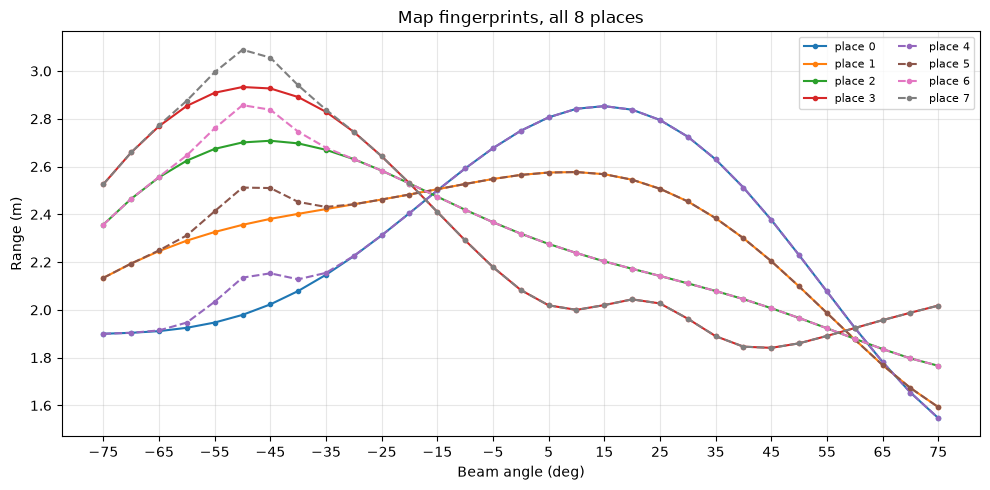

In [2]:
fig, ax = plt.subplots(figsize=(10, 5))
cm = plt.cm.tab10
for i in range(8):
    ax.plot(ang, R[i], color=cm(i), ls='-' if i < 4 else '--', marker='o', ms=3, label=names[i])
ax.set(xlabel='Beam angle (deg)', ylabel='Range (m)', title='Map fingerprints, all 8 places')
ax.set_xticks(ang[::2]); ax.grid(alpha=.3); ax.legend(ncol=2, fontsize=8)
plt.tight_layout(); plt.show()

### Each place

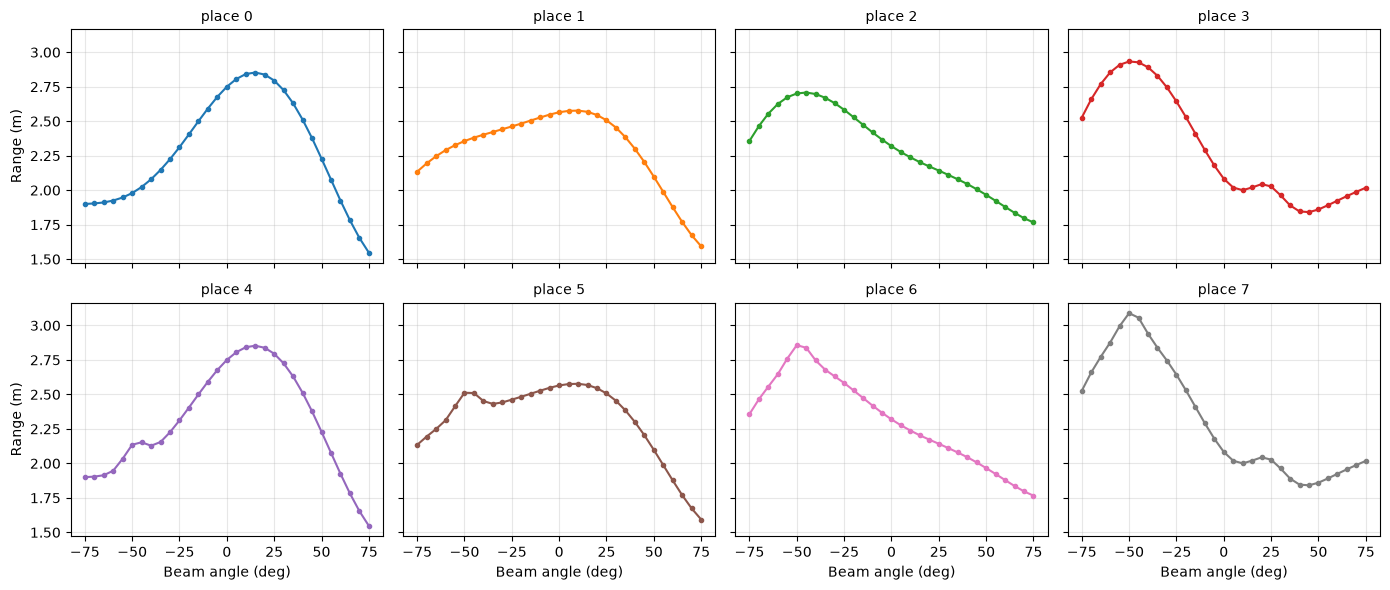

In [3]:
fig, axs = plt.subplots(2, 4, figsize=(14, 6), sharex=True, sharey=True)
for i, ax in enumerate(axs.ravel()):
    ax.plot(ang, R[i], color=cm(i), marker='o', ms=3)
    ax.set_title(names[i], fontsize=10); ax.grid(alpha=.3)
for ax in axs[1]: ax.set_xlabel('Beam angle (deg)')
for ax in axs[:, 0]: ax.set_ylabel('Range (m)')
plt.tight_layout(); plt.show()

### Look-alike pairs (i, i+4) and |difference|

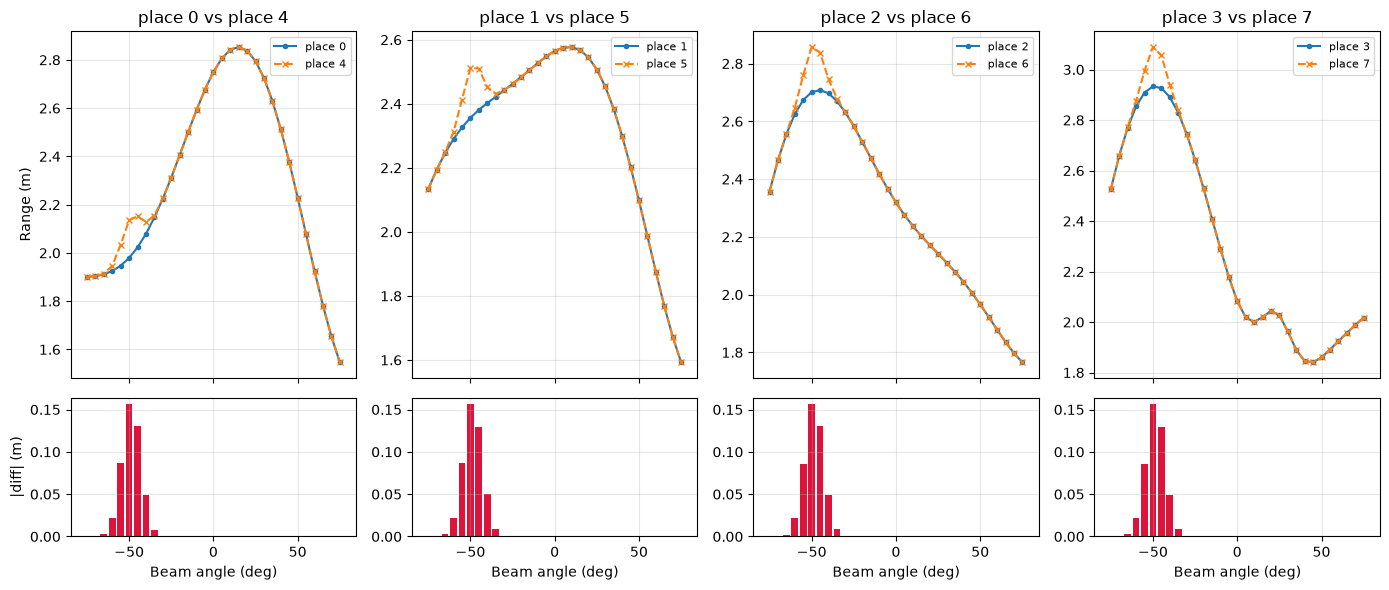

In [4]:
fig, axs = plt.subplots(2, 4, figsize=(14, 6), sharex=True, gridspec_kw={'height_ratios': [3, 1.2]})
for k in range(4):
    a, b = k, k + 4
    axs[0, k].plot(ang, R[a], 'o-', ms=3, label=names[a])
    axs[0, k].plot(ang, R[b], 'x--', ms=4, label=names[b])
    axs[0, k].set_title(f'{names[a]} vs {names[b]}'); axs[0, k].legend(fontsize=8); axs[0, k].grid(alpha=.3)
    axs[1, k].bar(ang, np.abs(R[a] - R[b]), width=4, color='crimson')
    axs[1, k].set_xlabel('Beam angle (deg)'); axs[1, k].grid(alpha=.3)
axs[0, 0].set_ylabel('Range (m)'); axs[1, 0].set_ylabel('|diff| (m)')
plt.tight_layout(); plt.show()

In [5]:
for k in range(4):
    d = np.abs(R[k] - R[k + 4])
    print(f'{names[k]} vs {names[k+4]}: mean |diff| = {d.mean():.3f} m, beams differing > 0.05 m: {ang[d > .05].tolist()} deg')

place 0 vs place 4: mean |diff| = 0.015 m, beams differing > 0.05 m: [-55, -50, -45] deg
place 1 vs place 5: mean |diff| = 0.015 m, beams differing > 0.05 m: [-55, -50, -45] deg
place 2 vs place 6: mean |diff| = 0.015 m, beams differing > 0.05 m: [-55, -50, -45] deg
place 3 vs place 7: mean |diff| = 0.015 m, beams differing > 0.05 m: [-55, -50, -45] deg


### Why the closest scan can fail
(0,4), (1,5), (2,6) and (3,7) are look-alikes: they differ only on beams −55°, −50°, −45° (up to 0.16 m). A noisy observation can land closer to the wrong twin, so nearest-scan matching alone can fail and other evidence (odometry, earlier belief) is needed.